# Exp-9 - K Nearest Neighbors algorithm

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [8]:
pd.set_option('display.max_columns', None)

In [9]:
data = pd.read_excel('NPS.xlsx')

In [10]:
data.head()

,Gender,Program,Year,Age,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Count_Promot,Count_Detract,NPS,Type
0,Male,MMS,FE,21,4,4,4,3,4,4,3,3,3,4,3,4,3,4,3,4,3,4,4,4,20,0,100,Promoter
1,Male,MMS,FE,25,4,4,3,3,3,3,3,3,4,4,4,4,4,4,4,3,4,3,3,4,20,0,100,Promoter
2,Male,MMS,FE,25,4,4,4,3,4,3,3,4,3,3,4,3,3,3,3,3,4,3,3,3,20,0,100,Promoter
3,Male,MMS,FE,22,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,20,0,100,Promoter
4,Male,MMS,FE,24,4,3,3,2,3,3,2,3,2,2,3,4,3,2,2,3,3,2,3,3,13,0,65,Promoter


In [11]:
# Separating x and y variables

x = data.drop(columns=['Gender', 'Program', 'Year','Age','Count_Promot','Count_Detract','NPS','Type'])

y = data['Type']

<Axes: xlabel='Type', ylabel='count'>

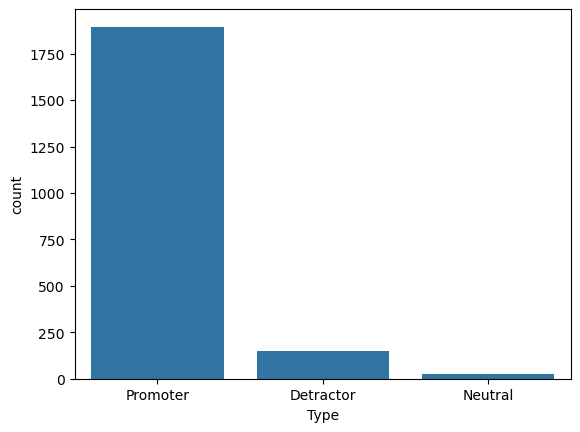

In [12]:
# check for balancea data

sns.countplot(data=data,x='Type')

In [13]:
data['Type'].value_counts()

Type
Promoter     1895
Detractor     148
Neutral        23
Name: count, dtype: int64

In [14]:
from imblearn.over_sampling import RandomOverSampler
over = RandomOverSampler()
x_os, y_os = over.fit_resample(x,y)

In [15]:
y_os.value_counts()

Type
Promoter     1895
Detractor    1895
Neutral      1895
Name: count, dtype: int64

In [16]:
# scaling the x input data

from sklearn.preprocessing import StandardScaler

sc = StandardScaler()
sc_x = sc.fit_transform(x_os)
print(sc_x)

[[ 1.08769926  1.47983669  1.42342628 ...  1.49007613  1.03566883
   1.55583827]
 [ 1.08769926  1.47983669  0.46713009 ...  0.65990337  0.16482468
   1.55583827]
 [ 1.08769926  1.47983669  1.42342628 ...  0.65990337  0.16482468
   0.64087597]
 ...
 [ 0.01843239 -0.71989441  0.46713009 ... -0.17026938 -0.70601947
   0.64087597]
 [ 0.01843239 -0.71989441  0.46713009 ... -0.17026938 -0.70601947
   0.64087597]
 [-1.05083447 -0.71989441 -0.48916611 ... -0.17026938 -0.70601947
  -0.27408633]]


In [17]:
from sklearn.model_selection import train_test_split

In [18]:
x_train, x_test, y_train,y_test = train_test_split(x_os,y_os,test_size=0.20,random_state=100)

In [19]:
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(4548, 20) (1137, 20) (4548,) (1137,)


In [20]:
from sklearn.neighbors import KNeighborsClassifier

In [21]:
knn = KNeighborsClassifier()

In [22]:
knn.fit(x_train,y_train)

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [23]:
# checking model accuracy

from sklearn.metrics import accuracy_score

y_pred = knn.predict(x_test)
accuracy_score(y_test, y_pred)


0.9920844327176781

In [25]:
error =[]
train_score =[]
test_score =[]

for i in range(2,11):
    nn = KNeighborsClassifier(n_neighbors=i)
    nn.fit(x_train,y_train)
    predicted = nn.predict(x_test)
    error.append(np.mean(predicted != y_test))
    train_score.append(nn.score(x_train, y_train))
    test_score.append(nn.score(x_test, y_test))


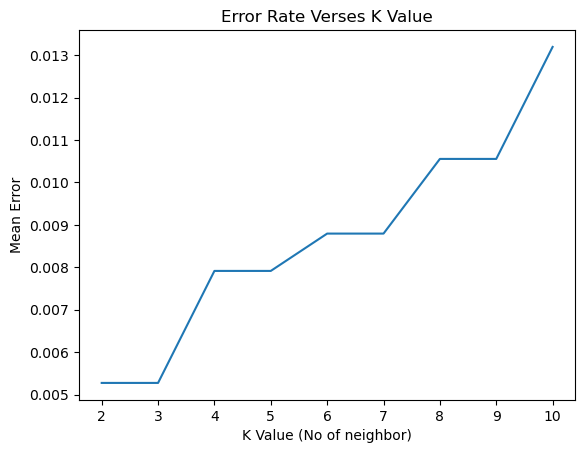

In [26]:
plt.plot(range(2,11),error)
plt.title('Error Rate Verses K Value')
plt.xlabel('K Value (No of neighbor)')
plt.ylabel('Mean Error')
plt.show()

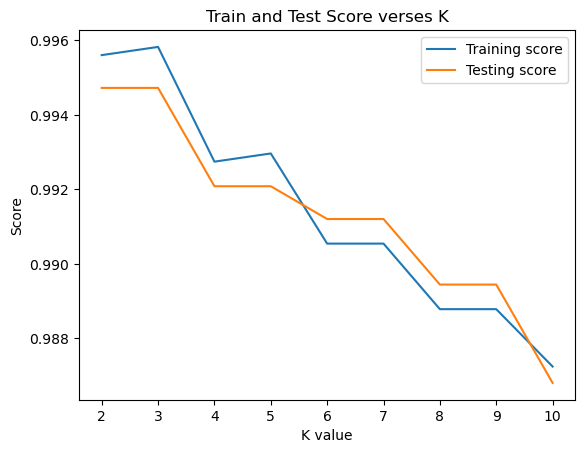

In [27]:
plt.plot(range(2,11),train_score,label='Training score')
plt.plot(range(2,11),test_score,label='Testing score')
plt.title('Train and Test Score verses K')
plt.xlabel('K value')
plt.ylabel('Score')
plt.legend(loc = 'upper right')
plt.show()


In [28]:
from sklearn.metrics import accuracy_score, classification_report,confusion_matrix


In [29]:
cm= confusion_matrix(y_pred,y_test)

Text(0.5, 1.0, 'Confusion Matrix')

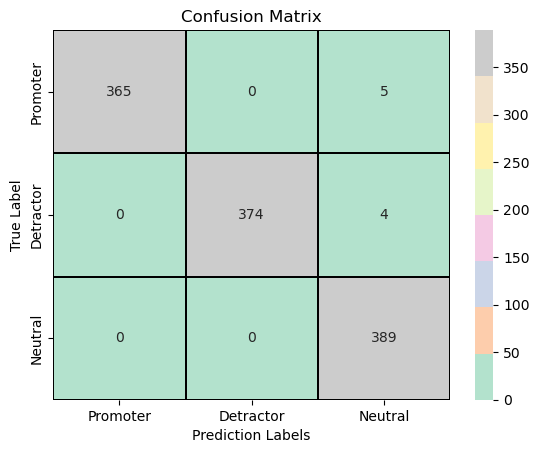

In [32]:
classes = ['Promoter', 'Detractor', 'Neutral']
sns.heatmap(cm,annot=True, linewidths=0.3, linecolor='black',cmap='Pastel2',fmt='d',xticklabels=classes,yticklabels=classes)
plt.xlabel('Prediction Labels')
plt.ylabel('True Label')
plt.title('Confusion Matrix')



In [33]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

   Detractor       0.99      1.00      0.99       365
     Neutral       0.99      1.00      0.99       374
    Promoter       1.00      0.98      0.99       398

    accuracy                           0.99      1137
   macro avg       0.99      0.99      0.99      1137
weighted avg       0.99      0.99      0.99      1137



In [34]:
data.head(20)

,Gender,Program,Year,Age,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,Q11,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Count_Promot,Count_Detract,NPS,Type
0,Male,MMS,FE,21,4,4,4,3,4,4,3,3,3,4,3,4,3,4,3,4,3,4,4,4,20,0,100,Promoter
1,Male,MMS,FE,25,4,4,3,3,3,3,3,3,4,4,4,4,4,4,4,3,4,3,3,4,20,0,100,Promoter
2,Male,MMS,FE,25,4,4,4,3,4,3,3,4,3,3,4,3,3,3,3,3,4,3,3,3,20,0,100,Promoter
3,Male,MMS,FE,22,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,4,20,0,100,Promoter
4,Male,MMS,FE,24,4,3,3,2,3,3,2,3,2,2,3,4,3,2,2,3,3,2,3,3,13,0,65,Promoter
5,Male,MMS,FE,24,4,3,3,3,3,3,2,3,3,3,3,3,3,3,3,3,3,3,3,3,19,0,95,Promoter
6,Male,MMS,FE,22,4,4,4,4,4,2,3,3,3,4,4,4,3,3,3,3,4,3,4,3,19,0,95,Promoter
7,Male,EXTC,FE,18,4,3,3,3,2,3,3,3,3,3,3,3,3,2,2,1,2,3,3,3,15,1,70,Promoter
8,Male,INFT,FE,18,4,3,3,2,2,3,0,2,4,4,1,3,3,4,4,3,3,4,3,4,15,2,65,Promoter
9,Male,CMPN,FE,18,4,3,4,4,3,4,4,4,4,4,4,4,4,4,4,4,4,4,3,4,20,0,100,Promoter


In [35]:
knn.predict([[2,2,1,0,1,2,0,1,0,0,1,0,1,0,0,1,1,2,2,1]])

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array(['Detractor'], dtype=object)

In [36]:
new_data=data[data['Type']=='Neutral']

In [37]:
knn.predict([[2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2,2]])

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array(['Neutral'], dtype=object)

- conclusion 
- we have disscussed about what is precison and  what is accuracy 
- In todays class we learned aboot KNN method 
- KNN method is used neighbour concept and used classification 
- it classifies data according the cluster 
- A neighbor is a data point that is closest or most similar to another data point
- KNN works by finding the K nearest data points to a new point and predicting its class based on the majority of      its neighbour
- in this we used this for questions